# Trees and Model Stability

Trees are notorious for being **unstable**: Small changes in the data can lead to noticeable or large changes in the tree. We're going to explore this phenomenon.

1. Check out the data set `heart_failure` and appropriately clean it.
2. Perform a train-test split for a specific seed (save the seed for reproducibility). Fit a tree and a linear model on the training data and evaluate their performance on the test data. Set aside the predictions these models make.
3. Repeat step 2 for three to five different seeds (save the seeds for reproducibility). How different are the trees that you get? Your linear model coefficients?. Set aside the predictions these models make.
4. Typically, you would see the trees changing what appears to be a non-trivial amount, while the linear model coefficients don't vary nearly as much. Often, the changes appear substantial. 
But are they? Instead of focusing on the tree or model coefficients, do three things:
    
    a. Make scatterplots of the predicted values on the test set from question 2 against the predicted values for the alternative models from part 3, separately for your trees and linear models. Do they appear reasonably similar?
    
    b. Compute the correlation between your model in part 2 and your alternative models in part 3, separately for your trees and linear models. Are they highly correlated or not?
    
    c. Run a simple linear regression of the predicted values on the test set from the alternative models on the predicted values from question 2, separately for your trees and linear models. Is the intercept close to zero? Is the slope close to 1? Is the $R^2$ close to 1?

5. Do linear models appear to have similar coefficients and predictions across train/test splits? Do trees?
6. True or false for this dataset, and explain: "Even if the models end up having a substantially different appearance, the predictions they generate are often very similar."

---

## *Phase 1: Solution without AI

Complete all questions in the following cells without generative AI. Then commit and push the
notebook before beginning Phase 2.

**Declaration:** I completed this version without generative AI.

**Student(s):** Dylan Wang, Lani Le, Yipeng Cao

**Date:** 11/16/2026

In [1]:
# import necessary libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.linear_model import LogisticRegression, LinearRegression
from sklearn.metrics import accuracy_score, mean_squared_error, r2_score
from scipy.stats import pearsonr

In [14]:
# 1. Check out the data set `heart_failure` and appropriately clean it.
df = pd.read_csv('data/heart_failure/heart_failure_clinical_records_dataset.csv')

# inspect the data
display(df.head())
print(df.shape)
print(df.info())
print(df.isna().sum())
print("Duplicate rows:", df.duplicated().sum())

# remove duplicate rows and rows with missing values
df = df.drop_duplicates().dropna().copy()

target = "DEATH_EVENT"
X = df.drop(columns=target)
y = df[target]

print("Cleaned shape:", df.shape)
print("Target values:", sorted(y.unique()))

,age,anaemia,creatinine_phosphokinase,diabetes,ejection_fraction,high_blood_pressure,platelets,serum_creatinine,serum_sodium,sex,smoking,time,DEATH_EVENT
0,75.0,0,582,0,20,1,265000.00,1.9,130,1,0,4,1
1,55.0,0,7861,0,38,0,263358.03,1.1,136,1,0,6,1
2,65.0,0,146,0,20,0,162000.00,1.3,129,1,1,7,1
3,50.0,1,111,0,20,0,210000.00,1.9,137,1,0,7,1
4,65.0,1,160,1,20,0,327000.00,2.7,116,0,0,8,1


(299, 13)
<class 'pandas.DataFrame'>
RangeIndex: 299 entries, 0 to 298
Data columns (total 13 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   age                       299 non-null    float64
 1   anaemia                   299 non-null    int64  
 2   creatinine_phosphokinase  299 non-null    int64  
 3   diabetes                  299 non-null    int64  
 4   ejection_fraction         299 non-null    int64  
 5   high_blood_pressure       299 non-null    int64  
 6   platelets                 299 non-null    float64
 7   serum_creatinine          299 non-null    float64
 8   serum_sodium              299 non-null    int64  
 9   sex                       299 non-null    int64  
 10  smoking                   299 non-null    int64  
 11  time                      299 non-null    int64  
 12  DEATH_EVENT               299 non-null    int64  
dtypes: float64(3), int64(10)
memory usage: 30.5 KB
None
age           

The dataset contained 299 rows and 13 columns. There were no missing values or duplicate rows, so cleaning did not remove any observations. I used the 12 clinical measurements as predictors and DEATH_EVENT as the outcome.

In [15]:
# 2. Perform a train-test split for a specific seed (save the seed for reproducibility). Fit a tree and a linear model on the training data and evaluate their performance on the test data. Set aside the predictions these models make.
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeRegressor
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

 
BASE_SEED = 20

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=BASE_SEED
)

tree_baseline = DecisionTreeRegressor(random_state=BASE_SEED)
linear_baseline = make_pipeline(
    StandardScaler(),
    LinearRegression()
)

tree_baseline.fit(X_train, y_train)
linear_baseline.fit(X_train, y_train)

tree_pred_baseline = tree_baseline.predict(X_test)
linear_pred_baseline = linear_baseline.predict(X_test)

def report_metrics(name, actual, predicted):
    mse = mean_squared_error(actual, predicted)
    rmse = np.sqrt(mse)
    r2 = r2_score(actual, predicted)
    print(f"{name}: MSE={mse:.4f}, RMSE={rmse:.4f}, R²={r2:.4f}")

report_metrics("Decision tree", y_test, tree_pred_baseline)
report_metrics("Linear regression", y_test, linear_pred_baseline)




Decision tree: MSE=0.2667, RMSE=0.5164, R²=-0.2864
Linear regression: MSE=0.1507, RMSE=0.3882, R²=0.2729


With seed 20, linear regression performed better than the decision tree on the test set. The linear model had an RMSE of 0.3882 and an R^2 of 0.2729, while the tree had an RMSE of 0.5164 and an R^2 of -0.2864. The negative R^2 means the tree performed worse than simply predicting the test-set average for every observation.

In [16]:
# 3. Repeat step 2 for three to five different seeds (save the seeds for reproducibility). How different are the trees that you get? Your linear model coefficients?. Set aside the predictions these models make.
from sklearn.tree import export_text

SEEDS = [7, 201, 199, 2026]

tree_models = {}
linear_models = {}
tree_predictions = {}
linear_predictions = {}
split_metrics = []

for seed in SEEDS:
    X_train_s, X_test_s, y_train_s, y_test_s = train_test_split(
        X, y, test_size=0.25, random_state=seed
    )

    tree = DecisionTreeRegressor(random_state=seed)
    linear = make_pipeline(StandardScaler(), LinearRegression())

    tree.fit(X_train_s, y_train_s)
    linear.fit(X_train_s, y_train_s)

    tree_models[seed] = tree
    linear_models[seed] = linear

    # evaluate on this seed's own test set
    split_metrics.append({
        "seed": seed,
        "tree_R2": r2_score(y_test_s, tree.predict(X_test_s)),
        "linear_R2": r2_score(y_test_s, linear.predict(X_test_s))
    })

    # save predictions on the same test set used in Question 2
    tree_predictions[seed] = tree.predict(X_test)
    linear_predictions[seed] = linear.predict(X_test)

print(pd.DataFrame(split_metrics).set_index("seed"))

# show each tree's rules to see how its structure changes
for seed, tree in tree_models.items():
    print(f"\nDecision tree for seed {seed}:")
    print(export_text(tree, feature_names=list(X.columns), max_depth=4))

coefficient_table = pd.DataFrame(
    {
        seed: model.named_steps["linearregression"].coef_
        for seed, model in linear_models.items()
    },
    index=X.columns
)

display(coefficient_table)


       tree_R2  linear_R2
seed                     
7    -0.096491   0.302833
201  -0.093482   0.269494
199  -0.059655   0.267488
2026 -0.064909   0.324934

Decision tree for seed 7:
|--- time <= 69.00
|   |--- creatinine_phosphokinase <= 80.50
|   |   |--- serum_sodium <= 134.50
|   |   |   |--- value: [1.00]
|   |   |--- serum_sodium >  134.50
|   |   |   |--- value: [0.00]
|   |--- creatinine_phosphokinase >  80.50
|   |   |--- ejection_fraction <= 72.50
|   |   |   |--- creatinine_phosphokinase <= 2018.00
|   |   |   |   |--- creatinine_phosphokinase <= 159.50
|   |   |   |   |   |--- truncated branch of depth 4
|   |   |   |   |--- creatinine_phosphokinase >  159.50
|   |   |   |   |   |--- value: [1.00]
|   |   |   |--- creatinine_phosphokinase >  2018.00
|   |   |   |   |--- platelets <= 284179.02
|   |   |   |   |   |--- value: [1.00]
|   |   |   |   |--- platelets >  284179.02
|   |   |   |   |   |--- value: [0.00]
|   |   |--- ejection_fraction >  72.50
|   |   |   |--- value

,7,201,199,2026
age,0.079786,0.077525,0.078940,0.082196
anaemia,-0.026211,-0.004689,0.003807,-0.007610
creatinine_phosphokinase,0.002193,0.019973,0.045319,0.036723
diabetes,-0.002544,-0.017043,0.018898,0.012011
ejection_fraction,-0.101002,-0.118066,-0.126644,-0.138226
high_blood_pressure,-0.023108,0.011515,0.004869,-0.016837
platelets,-0.030477,-0.015207,0.002873,-0.011163
serum_creatinine,0.078348,0.096218,0.043927,0.070128
serum_sodium,-0.031904,-0.003622,-0.050939,-0.047068
sex,-0.038447,-0.026758,0.001395,-0.023597


The trees changed across train/test splits: their rules depended on different split points and paths through the data. Their predictions on the baseline test set were also only moderately correlated with the seed-20 tree predictions, with correlations around 0.39–0.46.

The linear coefficients were more stable for some features than others. For example, the age coefficient had a standard deviation of about 0.002 across seeds; the coefficients for time and ejection fraction also stayed similar. Several smaller coefficients changed sign, though their values remained relatively close to zero.

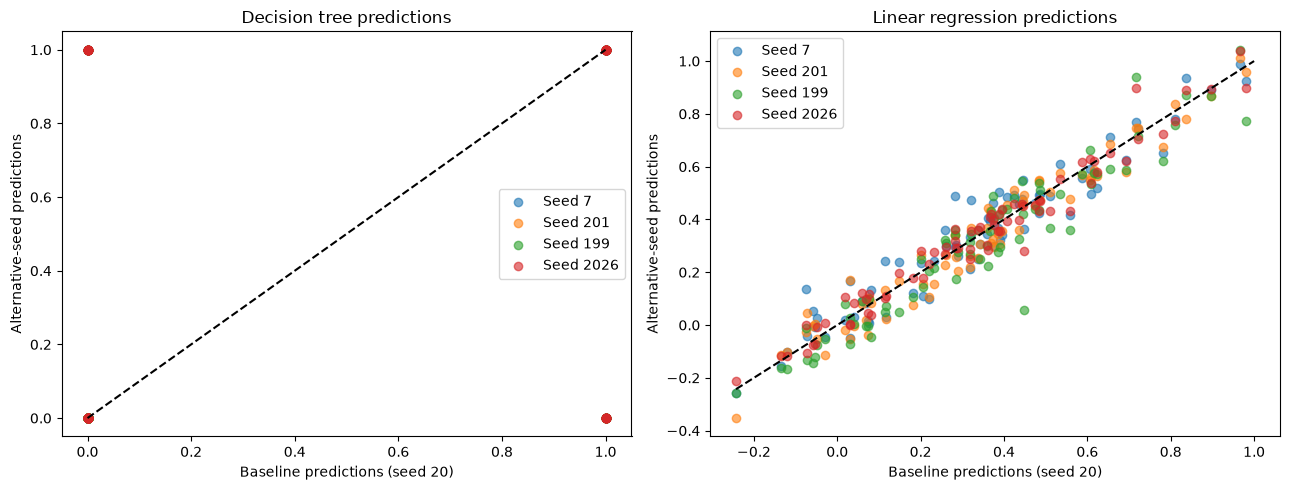

,model,seed,correlation,intercept,slope,R2
0,Tree,7,0.461261,0.163265,0.452119,0.212762
1,Tree,201,0.419314,0.142857,0.395604,0.175824
2,Tree,199,0.426934,0.163265,0.413658,0.182272
3,Tree,2026,0.387563,0.224490,0.390895,0.150205
4,Linear,7,0.961117,0.025502,0.944170,0.923746
5,Linear,201,0.976062,-0.009091,0.986686,0.952697
6,Linear,199,0.953807,-0.025352,0.990184,0.909748
7,Linear,2026,0.981686,0.013207,0.965096,0.963707


In [21]:
# 4. Typically, you would see the trees changing what appears to be a non-trivial amount, while the linear model coefficients don't vary nearly as much. Often, the changes appear substantial. 
# But are they? Instead of focusing on the tree or model coefficients, do three things:
    
#     a. Make scatterplots of the predicted values on the test set from question 2 against the predicted values for the alternative models from part 3, separately for your trees and linear models. Do they appear reasonably similar?


fig, axes = plt.subplots(1, 2, figsize=(13, 5))

for seed in SEEDS:
    axes[0].scatter(
        tree_pred_baseline,
        tree_predictions[seed],
        alpha=0.6,
        label=f"Seed {seed}"
    )
    axes[1].scatter(
        linear_pred_baseline,
        linear_predictions[seed],
        alpha=0.6,
        label=f"Seed {seed}"
    )

# diagonal line indicates identical predictions
for ax, baseline_preds, title in [
    (axes[0], tree_pred_baseline, "Decision tree predictions"),
    (axes[1], linear_pred_baseline, "Linear regression predictions")
]:
    low = min(baseline_preds.min(), 0)
    high = max(baseline_preds.max(), 1)
    ax.plot([low, high], [low, high], "k--")
    ax.set_xlabel("Baseline predictions (seed 20)")
    ax.set_ylabel("Alternative-seed predictions")
    ax.set_title(title)
    ax.legend()

plt.tight_layout()
plt.show()

#     b. Compute the correlation between your model in part 2 and your alternative models in part 3, separately for your trees and linear models. Are they highly correlated or not
#     c. Run a simple linear regression of the predicted values on the test set from the alternative models on the predicted values from question 2, separately for your trees and linear models. Is the intercept close to zero? Is the slope close to 1? Is the $R^2$ close to 1?
comparison_rows = []

for model_name, baseline_preds, alternatives in [
    ("Tree", tree_pred_baseline, tree_predictions),
    ("Linear", linear_pred_baseline, linear_predictions)
]:
    for seed, alt_preds in alternatives.items():
        # correlation between baseline and alternative predictions
        correlation = np.corrcoef(baseline_preds, alt_preds)[0, 1]

        # regress alternative predictions on baseline predictions
        comparison_model = LinearRegression()
        comparison_model.fit(baseline_preds.reshape(-1, 1), alt_preds)
        alt_from_baseline = comparison_model.predict(
            baseline_preds.reshape(-1, 1)
        )

        comparison_rows.append({
            "model": model_name,
            "seed": seed,
            "correlation": correlation,
            "intercept": comparison_model.intercept_,
            "slope": comparison_model.coef_[0],
            "R2": r2_score(alt_preds, alt_from_baseline)
        })

comparison_df = pd.DataFrame(comparison_rows)
display(comparison_df)





4a. Prediction scatterplots
The tree scatterplot shows substantial disagreement: many predictions fall away from the diagonal, and the tree predictions are often concentrated at 0 or 1. The linear model’s points cluster much closer to the diagonal, suggesting its predictions are more similar across splits.


4b–c. Correlation and regression comparison
The alternative tree predictions were not highly correlated with the baseline tree predictions: correlations ranged from about 0.39 to 0.46. Their regression slopes were about 0.39–0.45, intercepts about 0.14–0.22, and R^2 values about 0.15–0.21. These results indicate that tree predictions changed considerably across splits.

The linear model predictions were highly correlated with the baseline predictions, with correlations from about 0.95 to 0.98. Its regression intercepts were close to zero, slopes were about 0.94–0.99, and R^2 values were about 0.91–0.96. This indicates that linear predictions were quite similar across splits.

In [19]:
# 5. Do linear models appear to have similar coefficients and predictions across train/test splits? Do trees?
print("Linear coefficient spread across seeds:")
display(
    coefficient_table.assign(
        mean=coefficient_table.mean(axis=1),
        std=coefficient_table.std(axis=1)
    ).sort_values("std", ascending=False)
)

# correlation of each seed's predictions with the baseline predictions
prediction_stability = []

for model_name, baseline_preds, alternatives in [
    ("Tree", tree_pred_baseline, tree_predictions),
    ("Linear", linear_pred_baseline, linear_predictions)
]:
    for seed, alt_preds in alternatives.items():
        prediction_stability.append({
            "model": model_name,
            "seed": seed,
            "prediction_correlation_with_baseline":
                np.corrcoef(baseline_preds, alt_preds)[0, 1],
            "mean_absolute_prediction_difference":
                np.mean(np.abs(baseline_preds - alt_preds))
        })

display(pd.DataFrame(prediction_stability))

Linear coefficient spread across seeds:


,7,201,199,2026,mean,std
serum_creatinine,0.078348,0.096218,0.043927,0.070128,0.072155,0.021743
serum_sodium,-0.031904,-0.003622,-0.050939,-0.047068,-0.033383,0.021474
creatinine_phosphokinase,0.002193,0.019973,0.045319,0.036723,0.026052,0.019073
sex,-0.038447,-0.026758,0.001395,-0.023597,-0.021852,0.016762
high_blood_pressure,-0.023108,0.011515,0.004869,-0.016837,-0.005890,0.016683
diabetes,-0.002544,-0.017043,0.018898,0.012011,0.002831,0.015982
ejection_fraction,-0.101002,-0.118066,-0.126644,-0.138226,-0.120985,0.015675
time,-0.231445,-0.219472,-0.216727,-0.197298,-0.216235,0.014150
platelets,-0.030477,-0.015207,0.002873,-0.011163,-0.013493,0.013719
anaemia,-0.026211,-0.004689,0.003807,-0.007610,-0.008676,0.012654


,model,seed,prediction_correlation_with_baseline,mean_absolute_prediction_difference
0,Tree,7,0.461261,0.240000
1,Tree,201,0.419314,0.253333
2,Tree,199,0.426934,0.253333
3,Tree,2026,0.387563,0.280000
4,Linear,7,0.961117,0.060457
5,Linear,201,0.976062,0.053074
6,Linear,199,0.953807,0.067929
7,Linear,2026,0.981686,0.039682


The linear model’s most prominent coefficients were fairly consistent, and its predictions were stable across splits. Some smaller coefficients changed sign. The trees’ rules and predictions were less stable: their average prediction correlation with the baseline tree was about 0.42, with an average absolute prediction difference of about 0.26.

In [20]:
# 6. True or false for this dataset, and explain: "Even if the models end up having a substantially different appearance, the predictions they generate are often very similar."
stability_df = pd.DataFrame(prediction_stability)

print("Average prediction correlation with baseline:")
display(stability_df.groupby("model")[
    "prediction_correlation_with_baseline"
].mean())

print("\nAverage absolute prediction difference from baseline:")
display(stability_df.groupby("model")[
    "mean_absolute_prediction_difference"
].mean())

Average prediction correlation with baseline:


model
Linear    0.968168
Tree      0.423768
Name: prediction_correlation_with_baseline, dtype: float64


Average absolute prediction difference from baseline:


model
Linear    0.055286
Tree      0.256667
Name: mean_absolute_prediction_difference, dtype: float64

False. The linear models’ predictions were similar across splits, even when their coefficients shifted somewhat. But the tree predictions were not very similar across splits, despite being the same type of model. So the claim fits the linear models here, but not the trees.

## *Phase 2: AI-assisted Revision
Keep Phase 1 frozen.

- **Phase 1 commit SHA ID:** [To be provided]
- **AI tool and model used:** [To be provided]

### *Prompts used

1. [Paste prompt]
2. [Paste follow-up prompt]

### *AI-proposed changes


[Paste the AI's concise numbered list verbatim.]

1. ...
2. ...

### *Evaluation of AI suggestions


| Change | Decision | Reason and verification |
|---|---|---|
| 1 | Accept / modify / reject | ... |
| 2 | Accept / modify / reject | ... |

### *AI-assisted solution in full
After the evaluation of AI suggestions, incorporate the accepted revisions into your Phase 1 solution and provide the final Phase 2 solution in full in the following cells.

In [ ]:
# Your Phase 2 solution to the problem goes here.


### *Reflection on AI assistance
In your own words without generative AI.

[In 150–300 words, describe the main improvements, AI mistakes or limitations, how the final solution was verified, and any remaining concerns.]